# 07 — Economics

Real-terms NPV and IRR for 100 MW batteries at 1, 2 and 4 hours, with and without Capacity Credits.

Everything is in real 2025 Australian dollars, so the discount rate is a real rate and no inflation assumption is needed. Capital costs come from CSIRO GenCost 2025-26, Appendix Tables B.4 and B.5. Degradation is driven by the **modelled throughput** from notebook 04 rather than an assumed cycle count, and augmentation is costed at the battery-component price of the year it happens.

Results are reported as ranges. A single NPV would be misleading here: the revenue available to a SWIS battery fell by roughly three quarters between 2024 and 2026, so which year is annualised matters far more than the discount rate does.

In [1]:
import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if str(Path.cwd().parent) not in sys.path:
    sys.path.insert(0, str(Path.cwd().parent))

from src import cases, data, economics, viz
from src.economics import EconomicAssumptions, evaluate
from src.paths import OUTPUTS

viz.use_style()
pd.set_option("display.width", 240)
pd.set_option("display.max_columns", 60)

daily = pd.read_parquet(OUTPUTS / "strategy_daily.parquet")
daily["trading_date"] = pd.to_datetime(daily["trading_date"])
daily["year"] = daily["trading_date"].dt.year
print(f"{len(daily):,} daily rows from the strategy run")

26,832 daily rows from the strategy run


## Revenue inputs

Annualised from the realisable dispatch. The strategy used is the best of the naive forecasts, which is the honest floor; a trading desk that forecasts better than "the same time yesterday" earns more.

In [2]:
STRATEGY = "yesterday"

annualised = (
    daily[daily["strategy"].isin([STRATEGY, "perfect_foresight"])]
    .groupby(["case", "strategy", "year"], observed=True)
    .agg(days=("trading_date", "nunique"), revenue=("total_revenue", "sum"), cycles=("cycles", "sum"))
    .reset_index()
)
annualised["revenue_per_mw_year"] = (
    annualised["revenue"] / cases.HEADLINE_MW / (annualised["days"] / 365.25)
)
annualised["cycles_per_year"] = annualised["cycles"] / (annualised["days"] / 365.25)

view = annualised[annualised["strategy"] == STRATEGY].pivot_table(
    index="case", columns="year", values="revenue_per_mw_year", observed=True
)
print(f"realisable revenue, $/MW-year, '{STRATEGY}' forecast")
view.round(0)

realisable revenue, $/MW-year, 'yesterday' forecast


year,2023,2024,2025,2026
case,,,,
1h_credits,51995.0,104694.0,36282.0,-1920.0
1h_merchant,45810.0,100840.0,35014.0,-3070.0
2h_credits,112573.0,171135.0,54959.0,2.0
2h_merchant,104208.0,164816.0,54125.0,-1723.0
4h_credits,200015.0,266056.0,81134.0,4850.0
4h_merchant,191604.0,259345.0,83474.0,3390.0


## Capacity revenue

A battery holding Capacity Credits is credited for the capacity it can sustain over the four-hour obligation duration, net of discharge losses and the reserved state-of-charge window (assumption C1). The Reserve Capacity Price is the published figure for each capacity year (C5).

In [3]:
rows = []
for duration in cases.HEADLINE_DURATIONS_H:
    params = cases.battery(duration, has_capacity_credits=True)
    for year in (2023, 2024, 2025, 2026):
        price = data.reserve_capacity_price(year)
        rows.append(
            {
                "duration_h": duration,
                "capacity_year": f"{year}-{str(year + 1)[2:]}",
                "credited_mw": params.accredited_capacity_mw,
                "credited_share": params.accredited_capacity_mw / params.p_max_mw,
                "reserve_capacity_price": price,
                "capacity_revenue_per_mw_year": (
                    params.accredited_capacity_mw * price / params.p_max_mw if price else np.nan
                ),
            }
        )
capacity = pd.DataFrame(rows)
capacity.pivot_table(
    index="duration_h",
    columns="capacity_year",
    values="capacity_revenue_per_mw_year",
    observed=True,
).round(0)

capacity_year,2023-24,2024-25,2025-26,2026-27
duration_h,,,,
1.0,22363.0,41113.0,53067.0,45610.0
2.0,44725.0,82225.0,106134.0,91220.0
4.0,89450.0,164451.0,212268.0,182441.0


## Capital costs

In [4]:
cost_rows = []
for duration in (1.0, 2.0, 4.0):
    assumptions = EconomicAssumptions(duration_h=duration)
    entry = assumptions.gencost_entry
    cost_rows.append(
        {
            "duration_h": duration,
            "energy MWh": assumptions.energy_mwh,
            "$/kWh (GenCost)": entry["total_per_kwh"],
            "battery $/kWh": entry["battery_per_kwh"],
            "balance of plant $/kWh": entry["bop_per_kwh"],
            "plant capex $m": assumptions.plant_capex / 1e6,
            "total capex $m": assumptions.total_capex / 1e6,
            "$/kW installed": assumptions.total_capex / (assumptions.p_max_mw * 1000),
            "annual fixed O&M $m": assumptions.annual_fom / 1e6,
        }
    )
print(economics.GENCOST_CITATION)
pd.DataFrame(cost_rows).set_index("duration_h").round(2)

CSIRO GenCost 2025-26 Final Report, Apx Tables B.4 and B.5 (pp. 73-74), Current policies scenario, 2025 values


,energy MWh,$/kWh (GenCost),battery $/kWh,balance of plant $/kWh,plant capex $m,total capex $m,$/kW installed,annual fixed O&M $m
duration_h,,,,,,,,
1.0,100.0,778.0,310.0,467.0,77.8,85.58,855.8,1.71
2.0,200.0,525.0,290.0,235.0,105.0,115.50,1155.0,2.31
4.0,400.0,385.0,265.0,120.0,154.0,169.40,1694.0,3.39


## Scenario grid

Each duration against each revenue year, merchant and with Capacity Credits. The breakeven column is the annual revenue per MW that would bring the NPV to zero; comparing it with the revenue column is the quickest read of how far from viable each case is.

In [5]:
realisable = annualised[annualised["strategy"] == STRATEGY]

def revenue_for(duration: float, regime: str, year: int) -> float:
    label = f"{duration:g}h_{regime}"
    rows = realisable[(realisable["case"] == label) & (realisable["year"] == year)]
    return float(rows["revenue_per_mw_year"].iloc[0]) if len(rows) else np.nan


def cycles_for(duration: float, regime: str, year: int) -> float:
    label = f"{duration:g}h_{regime}"
    rows = realisable[(realisable["case"] == label) & (realisable["year"] == year)]
    return float(rows["cycles_per_year"].iloc[0]) if len(rows) else np.nan


grid_rows = []
for duration in cases.HEADLINE_DURATIONS_H:
    params = cases.battery(duration, has_capacity_credits=True)
    for year in (2024, 2025, 2026):
        price = data.reserve_capacity_price(year)
        capacity_per_mw = params.accredited_capacity_mw * price / params.p_max_mw
        for regime, capacity_revenue in (("merchant", 0.0), ("credits", capacity_per_mw)):
            trading = revenue_for(duration, regime, year)
            cycles = cycles_for(duration, regime, year)
            assumptions = EconomicAssumptions(
                duration_h=duration,
                annual_revenue=trading * cases.HEADLINE_MW,
                annual_capacity_revenue=capacity_revenue * cases.HEADLINE_MW,
                cycles_per_year=cycles,
            )
            result = evaluate(assumptions)
            grid_rows.append(
                {
                    "duration_h": duration,
                    "revenue_year": year,
                    "regime": regime,
                    "trading $/MW-yr": trading,
                    "capacity $/MW-yr": capacity_revenue,
                    "total $/MW-yr": trading + capacity_revenue,
                    "cycles/yr": cycles,
                    "capex $/kW": result["capex_per_kw"],
                    "breakeven $/MW-yr": result["levelised_revenue_requirement"],
                    "NPV $m": result["npv"] / 1e6,
                    "IRR": result["irr"],
                    "augmentations": result["augmentations"],
                }
            )

grid = pd.DataFrame(grid_rows)
grid.to_csv(OUTPUTS / "economics_grid.csv", index=False)
grid.set_index(["revenue_year", "duration_h", "regime"]).round(2)

trading $/MW-yr  capacity $/MW-yr  total $/MW-yr  cycles/yr  capex $/kW  breakeven $/MW-yr  NPV $m   IRR  augmentations
revenue_year duration_h regime                                                                                                                           
2024         1.0        merchant        100840.25              0.00      100840.25    1892.29       855.8          130527.99  -29.75  0.02             10
                        credits         104694.19          41112.71      145806.90    1806.85       855.8          129118.76   16.76  0.09             10
2025         1.0        merchant         35014.00              0.00       35014.00    1001.80       855.8          122276.18  -84.03   NaN              5
                        credits          36281.55          53066.89       89348.44     969.09       855.8          121545.20  -31.09  0.02              5
2026         1.0        merchant         -3070.25              0.00       -3070.25     806.69       855.8          117972.53 -118.46   NaN              5
                        credits          -1919.81          45610.21       43690.40     762.77       855.8          119388.25  -72.49 -0.11              4
2024         2.0        merchant        164815.83              0.00      164815.83    1088.67      1155.0          175959.76  -10.65  0.06              5
                        credits         171134.77          82225.42      253360.19    1052.35      1155.0          174590.13   75.53  0.15              5
2025         2.0        merchant         54124.55              0.00       54124.55     716.09      1155.0          165088.26 -106.81   NaN              4
                        credits          54958.51         106133.79      161092.30     709.84      1155.0          164839.04   -3.61  0.07              4
2026         2.0        merchant         -1722.81              0.00       -1722.81     584.35      1155.0          161458.91 -156.50   NaN              3
                        credits              1.53          91220.43       91221.96     568.78      1155.0          160811.45  -66.88 -0.02              3
2024         4.0        merchant        259344.79              0.00      259344.79     633.61      1694.0          243850.56   15.05  0.08              4
                        credits         266056.21         164450.84      430507.04     631.29      1694.0          243696.80  181.49  0.19              4
2025         4.0        merchant         83474.19              0.00       83474.19     505.93      1694.0          237125.65 -148.90 -0.12              3
                        credits          81134.00         212267.58      293401.58     505.57      1694.0          237101.79   54.56  0.11              3
2026         4.0        merchant          3390.14              0.00        3390.14     405.19      1694.0          231560.43 -219.87   NaN              2
                        credits           4850.49         182440.85      187291.34     403.09      1694.0          231414.55  -42.53  0.03              2

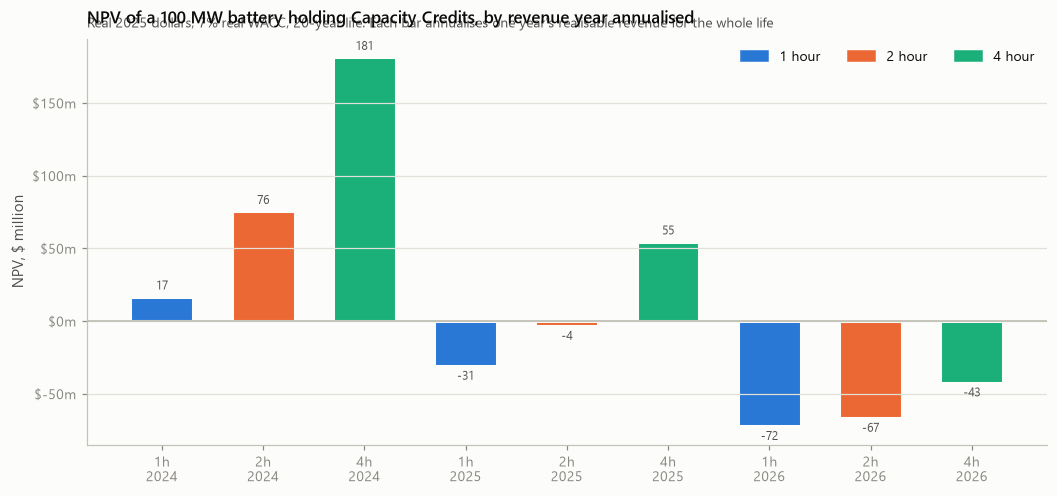

In [6]:
fig, ax = viz.figure(9.5, 4.4)

labels = []
values = []
colours = []
for year in (2024, 2025, 2026):
    for duration in cases.HEADLINE_DURATIONS_H:
        row = grid[
            (grid["revenue_year"] == year)
            & (grid["duration_h"] == duration)
            & (grid["regime"] == "credits")
        ].iloc[0]
        labels.append(f"{duration:g}h\n{year}")
        values.append(row["NPV $m"])
        colours.append(viz.DURATION_COLOURS[duration])

x = np.arange(len(labels))
bars = ax.bar(x, values, color=colours, width=0.62, linewidth=2, edgecolor=viz.SURFACE)
ax.bar_label(bars, fmt="%.0f", padding=3, fontsize=8, color=viz.INK_SECONDARY)
ax.axhline(0, color=viz.AXIS, linewidth=1.2)
ax.set_xticks(x)
ax.set_xticklabels(labels)
viz.money(ax, unit="m")
viz.finish(
    ax,
    "NPV of a 100 MW battery holding Capacity Credits, by revenue year annualised",
    subtitle="Real 2025 dollars, 7% real WACC, 20-year life. Each bar annualises one year's realisable revenue for the whole life",
    ylabel="NPV, $ million",
)
handles = [plt.Rectangle((0, 0), 1, 1, color=viz.DURATION_COLOURS[d]) for d in cases.HEADLINE_DURATIONS_H]
ax.legend(handles, [f"{d:g} hour" for d in cases.HEADLINE_DURATIONS_H], loc="upper right", ncols=3)
plt.show()

## Revenue against the breakeven requirement

The clearest single view: the bar is what the battery earns, the marker is what it needs to earn.

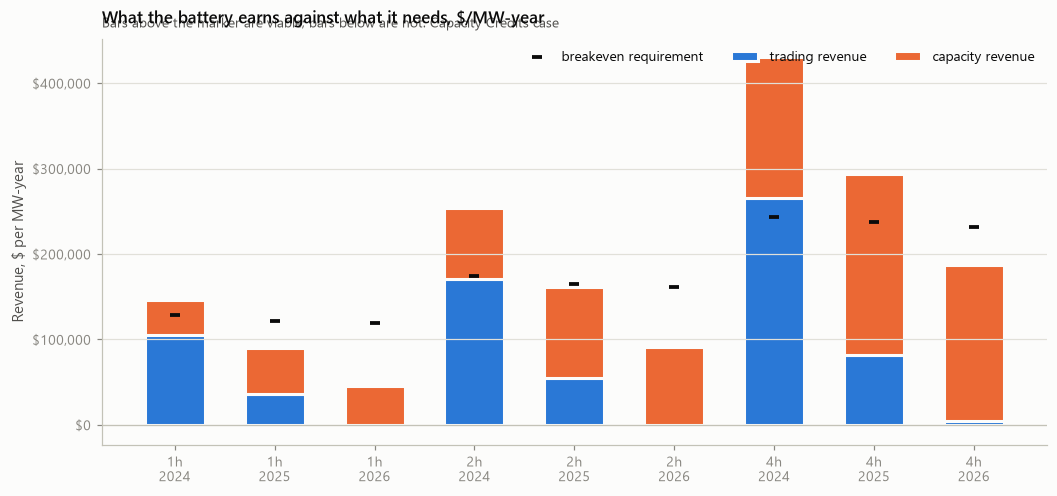

In [7]:
fig, ax = viz.figure(9.5, 4.4)

subset = grid[grid["regime"] == "credits"].copy()
subset["label"] = subset["duration_h"].map(lambda d: f"{d:g}h") + "\n" + subset["revenue_year"].astype(str)
x = np.arange(len(subset))

ax.bar(x, subset["trading $/MW-yr"], color=viz.SERIES[0], label="trading revenue",
       width=0.6, linewidth=2, edgecolor=viz.SURFACE)
ax.bar(x, subset["capacity $/MW-yr"], bottom=subset["trading $/MW-yr"].clip(lower=0),
       color=viz.SERIES[1], label="capacity revenue", width=0.6, linewidth=2, edgecolor=viz.SURFACE)
ax.scatter(x, subset["breakeven $/MW-yr"], color=viz.INK_PRIMARY, zorder=5, s=36,
           marker="_", linewidths=2.5, label="breakeven requirement")

ax.axhline(0, color=viz.AXIS, linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(subset["label"])
viz.money(ax)
viz.finish(
    ax,
    "What the battery earns against what it needs, $/MW-year",
    subtitle="Bars above the marker are viable; bars below are not. Capacity Credits case",
    ylabel="Revenue, $ per MW-year",
)
ax.legend(loc="upper right", ncols=3)
plt.show()

## Degradation and augmentation

Driven by the modelled throughput, which differs sharply by duration: a one-hour battery cycles several times a day, a four-hour battery less than once.

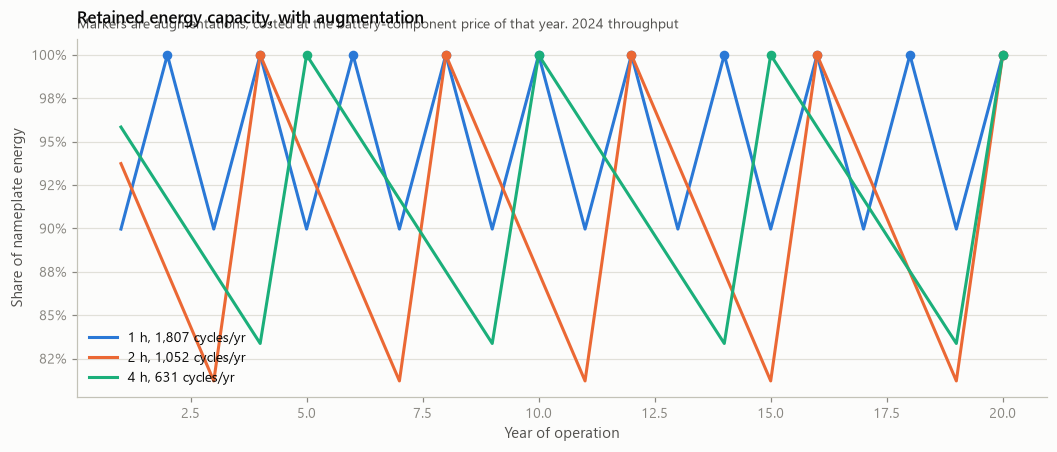

In [8]:
fig, ax = viz.figure(9.5, 4.0)

for duration in cases.HEADLINE_DURATIONS_H:
    cycles = cycles_for(duration, "credits", 2024)
    trajectory = economics.capacity_trajectory(
        EconomicAssumptions(duration_h=duration, cycles_per_year=cycles)
    )
    colour = viz.DURATION_COLOURS[duration]
    ax.plot(trajectory.index, trajectory["retained_capacity"], color=colour,
            label=f"{duration:g} h, {cycles:,.0f} cycles/yr")
    augmented = trajectory[trajectory["augmented"]]
    ax.scatter(augmented.index, augmented["retained_capacity"], color=colour, s=28, zorder=5)

viz.percent(ax)
ax.set_xlabel("Year of operation")
viz.finish(
    ax,
    "Retained energy capacity, with augmentation",
    subtitle="Markers are augmentations, costed at the battery-component price of that year. 2024 throughput",
    ylabel="Share of nameplate energy",
)
ax.legend(loc="lower left")
plt.show()

## Tornado chart

One parameter at a time, around the 2-hour 2025-revenue case with Capacity Credits. 2025 is used as the central case because 2024 was exceptional and 2026 is a partial year.

In [9]:
central_row = grid[
    (grid["duration_h"] == 2.0) & (grid["revenue_year"] == 2025) & (grid["regime"] == "credits")
].iloc[0]

base = EconomicAssumptions(
    duration_h=2.0,
    annual_revenue=central_row["trading $/MW-yr"] * cases.HEADLINE_MW,
    annual_capacity_revenue=central_row["capacity $/MW-yr"] * cases.HEADLINE_MW,
    cycles_per_year=central_row["cycles/yr"],
)

variations = {
    "annual_revenue": (base.annual_revenue * 0.5, base.annual_revenue * 2.0),
    "annual_capacity_revenue": (
        base.annual_capacity_revenue * 0.5,
        base.annual_capacity_revenue * 1.5,
    ),
    "capex_per_kwh": (525.0 * 0.75, 525.0 * 1.25),
    "real_wacc": (0.05, 0.10),
    "fom_share_of_capex": (0.01, 0.03),
    "cycle_life": (4000.0, 10000.0),
    "calendar_fade_per_year": (0.005, 0.02),
    "cycles_per_year": (base.cycles_per_year * 0.5, base.cycles_per_year * 1.5),
    "project_life_years": (15, 25),
    "development_share": (0.05, 0.20),
}
tornado = economics.tornado(base, variations)
tornado[["low_input", "high_input", "low", "high", "baseline", "swing"]].round(0)

,low_input,high_input,low,high,baseline,swing
parameter,,,,,,
calendar_fade_per_year,0.0,0.0,-46.0,-75671.0,-36090.0,75625.0
cycle_life,4000.0,10000.0,-126972.0,41149.0,-36090.0,168120.0
development_share,0.0,0.0,27534.0,-163337.0,-36090.0,190871.0
cycles_per_year,355.0,1065.0,62567.0,-133772.0,-36090.0,196338.0
fom_share_of_capex,0.0,0.0,86271.0,-158451.0,-36090.0,244722.0
project_life_years,15.0,25.0,-197172.0,79011.0,-36090.0,276183.0
real_wacc,0.0,0.0,155390.0,-249787.0,-36090.0,405176.0
capex_per_kwh,394.0,656.0,313841.0,-386020.0,-36090.0,699861.0
annual_revenue,2747926.0,10991702.0,-300778.0,493287.0,-36090.0,794066.0


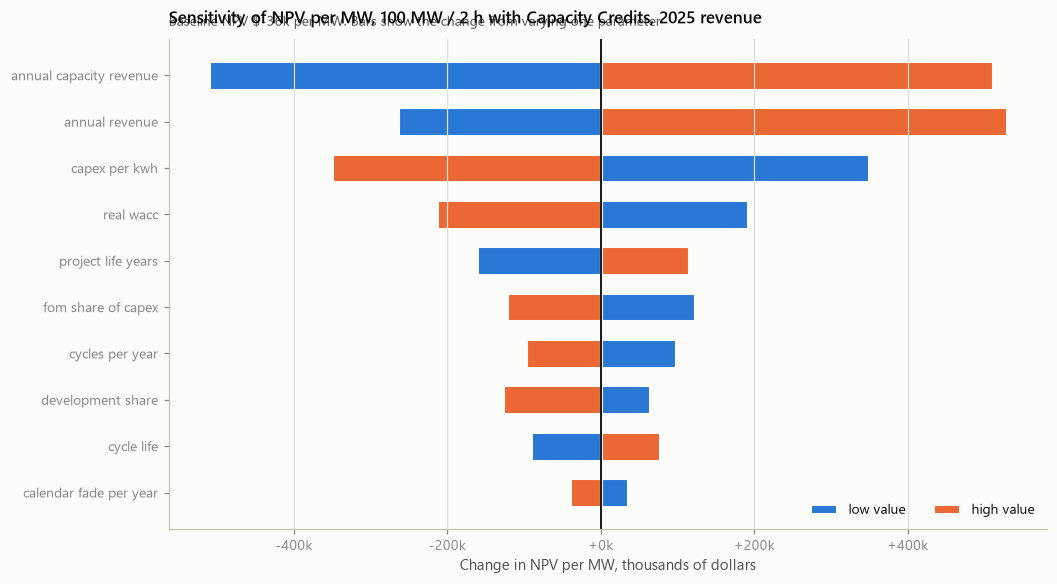

In [10]:
fig, ax = viz.figure(9.5, 5.2)

y = np.arange(len(tornado))
baseline = tornado["baseline"].iloc[0] / 1e3
low = tornado["low"] / 1e3 - baseline
high = tornado["high"] / 1e3 - baseline

ax.barh(y, low, color=viz.SERIES[0], height=0.62, linewidth=2, edgecolor=viz.SURFACE, label="low value")
ax.barh(y, high, color=viz.SERIES[1], height=0.62, linewidth=2, edgecolor=viz.SURFACE, label="high value")
ax.axvline(0, color=viz.INK_PRIMARY, linewidth=1.2)

ax.set_yticks(y)
ax.set_yticklabels([p.replace("_", " ") for p in tornado.index])
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+,.0f}k"))
viz.finish(
    ax,
    "Sensitivity of NPV per MW, 100 MW / 2 h with Capacity Credits, 2025 revenue",
    subtitle=f"Baseline NPV ${baseline:,.0f}k per MW. Bars show the change from varying one parameter",
    ylabel=None,
)
ax.set_xlabel("Change in NPV per MW, thousands of dollars")
ax.legend(loc="lower right", ncols=2)
plt.show()

## The range, not a number

Spanning the revenue years and the WACC range, for each duration. The spread across revenue years is far wider than the spread across any financial assumption, which is the point.

In [11]:
range_rows = []
for duration in cases.HEADLINE_DURATIONS_H:
    params = cases.battery(duration, has_capacity_credits=True)
    npvs = []
    irrs = []
    for year in (2024, 2025, 2026):
        price = data.reserve_capacity_price(year)
        capacity_per_mw = params.accredited_capacity_mw * price / params.p_max_mw
        for wacc in (0.05, 0.07, 0.10):
            result = evaluate(
                EconomicAssumptions(
                    duration_h=duration,
                    real_wacc=wacc,
                    annual_revenue=revenue_for(duration, "credits", year) * cases.HEADLINE_MW,
                    annual_capacity_revenue=capacity_per_mw * cases.HEADLINE_MW,
                    cycles_per_year=cycles_for(duration, "credits", year),
                )
            )
            npvs.append(result["npv"] / 1e6)
            irrs.append(result["irr"])
    range_rows.append(
        {
            "duration_h": duration,
            "NPV low $m": min(npvs),
            "NPV median $m": float(np.median(npvs)),
            "NPV high $m": max(npvs),
            "IRR low": np.nanmin(irrs),
            "IRR median": np.nanmedian(irrs),
            "IRR high": np.nanmax(irrs),
        }
    )

ranges = pd.DataFrame(range_rows).set_index("duration_h")
ranges.to_csv(OUTPUTS / "economics_ranges.csv")
ranges.round(3)

,NPV low $m,NPV median $m,NPV high $m,IRR low,IRR median,IRR high
duration_h,,,,,,
1.0,-74.727,-31.089,35.058,-0.112,0.017,0.094
2.0,-75.916,-3.609,108.816,-0.023,0.066,0.147
4.0,-66.707,54.563,242.384,0.035,0.110,0.193
